# Multi-Class Classification Pipeline: Iris Dataset
**Goal:** Build an end-to-end supervised classification pipeline with Scikit-Learn: feature scaling, an 80/20 train/test split, Logistic Regression vs. Decision Tree, and a benchmark of accuracy, precision, recall and F1-score, with confusion matrices and decision-boundary plots.

**Pipeline:**
1. Load the data with Pandas
2. Exploratory pairplot (Seaborn)
3. Train/test split (80/20, stratified)
4. Scale features with `StandardScaler` (fit on the training set only, to avoid data leakage)
5. Train `LogisticRegression` and `DecisionTreeClassifier`
6. Evaluate: accuracy, precision, recall, F1, classification report
7. Confusion matrix heatmaps
8. Decision-boundary visualization
9. Benchmark comparison and conclusions

In [7]:
!pip install numpy pandas matplotlib seaborn scikit-learn

     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/80.3 kB ? eta -:--:--
     ----------------------------- -------- 61.4/80.3 kB 812.7 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 897.7 kB/s eta 0:00:00
     ---------------------------------------- 0.0/142.6 kB ? eta -:--:--
     --------------------------- ---------- 102.4/142.6 kB 3.0 MB/s eta 0:00:01
     -------------------------------------- 142.6/142.6 kB 2.1 MB/s eta 0:00:00
     ---------------------------------------- 0.0/61.0 kB ? eta -:--:--
     ---------------------------------------- 61.0/61.0 kB 3.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB 7.9 MB/s eta 0:00:02
   -- ------------------------------------- 0.8/12.6 MB 8.1 MB/s eta 0:00:02
   --- ------------------------------------ 1.1/12.6 MB 8.0 MB/s eta 0:00:02
   ------


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\eshap\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [8]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")

## 1. Load the dataset

In [9]:
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

try:
    df = pd.read_csv(URL)
    print("Loaded Iris from the seaborn-data GitHub URL.")
except Exception as e:
    # Offline fallback: the identical dataset ships with scikit-learn
    from sklearn.datasets import load_iris
    iris = load_iris(as_frame=True)
    df = iris.frame.copy()
    df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "target"]
    df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
    df = df.drop(columns="target")
    print("No internet, loaded Iris from scikit-learn instead.")

print("Shape:", df.shape)
df.head()

Loaded Iris from the seaborn-data GitHub URL.
Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [10]:
print(df.info())
print("\nMissing values per column:\n", df.isna().sum())
print("\nClass distribution:\n", df["species"].value_counts())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB
None

Missing values per column:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Class distribution:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


## 2. Exploratory data analysis

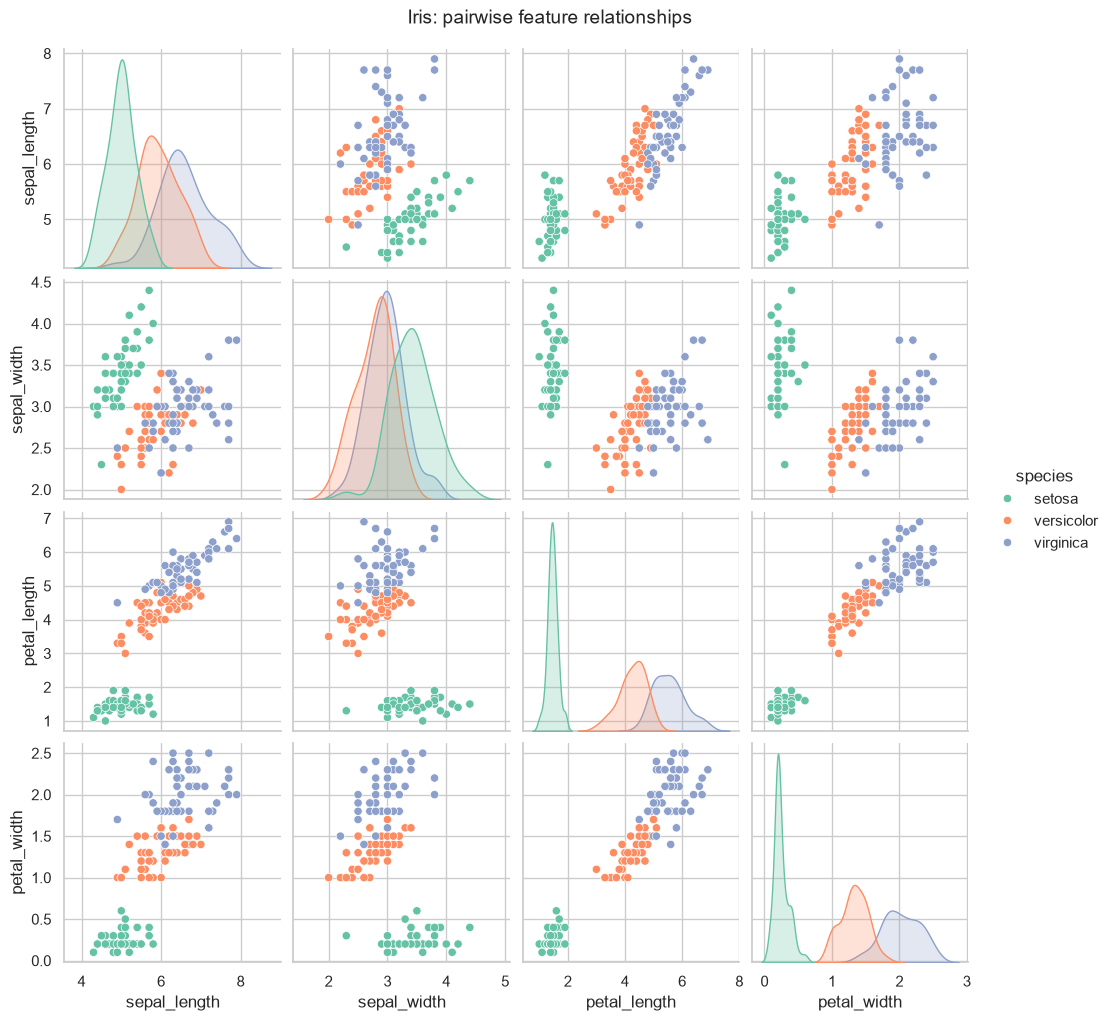

In [11]:
sns.pairplot(df, hue="species", diag_kind="kde", palette="Set2", corner=False)
plt.suptitle("Iris: pairwise feature relationships", y=1.02, fontsize=14)
plt.show()

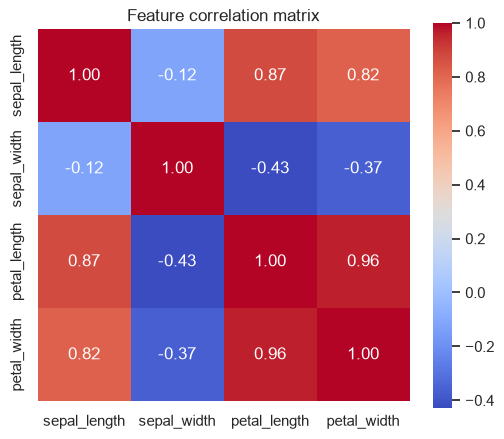

In [12]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.drop(columns="species").corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Feature correlation matrix")
plt.show()

**Observations:** *setosa* is linearly separable from the other two classes, especially along the petal dimensions. *versicolor* and *virginica* overlap slightly, so that is where any misclassifications will happen. Petal length and petal width are strongly correlated (~0.96).

## 3. Feature/target split and 80/20 train-test split

In [13]:
X = df.drop(columns="species")
y = df["species"]
class_names = sorted(y.unique())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Train: {X_train.shape[0]} samples | Test: {X_test.shape[0]} samples")
print("\nTrain class balance:\n", y_train.value_counts())

Train: 120 samples | Test: 30 samples

Train class balance:
 species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64


## 4. Feature scaling with `StandardScaler`
The scaler is **fit on the training data only** and then applied to the test data, so no test-set information leaks into training.

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pd.DataFrame({
    "mean (train, scaled)": X_train_scaled.mean(axis=0).round(3),
    "std (train, scaled)": X_train_scaled.std(axis=0).round(3),
}, index=X.columns)

,"mean (train, scaled)","std (train, scaled)"
sepal_length,-0.0,1.0
sepal_width,0.0,1.0
petal_length,0.0,1.0
petal_width,0.0,1.0


## 5. Train the models

In [15]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
dec_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)

log_reg.fit(X_train_scaled, y_train)
dec_tree.fit(X_train_scaled, y_train)

models = {"Logistic Regression": log_reg, "Decision Tree": dec_tree}
predictions = {name: m.predict(X_test_scaled) for name, m in models.items()}
print("Models trained.")

Models trained.


## 6. Evaluation: classification reports

In [16]:
for name, y_pred in predictions.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

Logistic Regression
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

Decision Tree
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     0.900     0.947        10
   virginica      0.909     1.000     0.952        10

    accuracy                          0.967        30
   macro avg      0.970     0.967     0.967        30
weighted avg      0.970     0.967     0.967        30



In [17]:
rows = []
for name, y_pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
    })
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9667,0.9697,0.9667,0.9666


## 7. Confusion matrix heatmaps

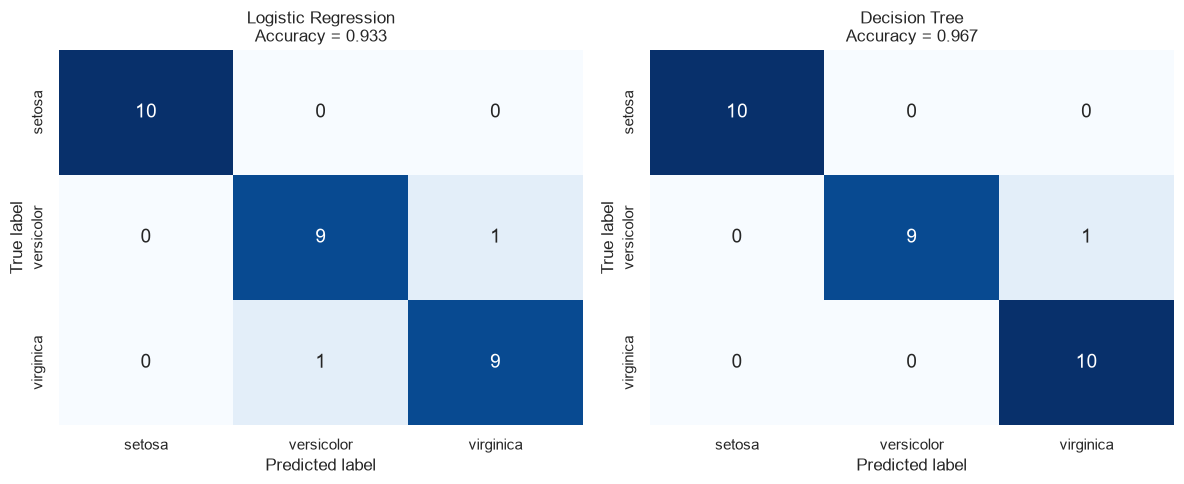

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=class_names)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax,
                annot_kws={"size": 14})
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, y_pred):.3f}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.tight_layout()
plt.show()

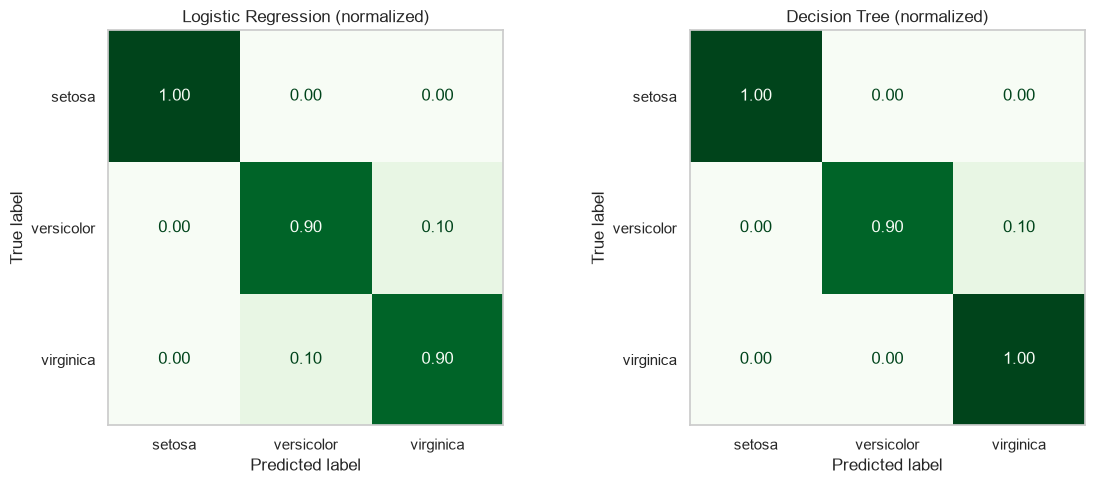

In [19]:
# Row-normalized view (per-class recall)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=class_names, normalize="true",
        cmap="Greens", values_format=".2f", ax=ax, colorbar=False)
    ax.set_title(f"{name} (normalized)")
    ax.grid(False)
plt.tight_layout()
plt.show()

## 8. Decision-boundary visualization
Decision boundaries can only be drawn in 2D, so we retrain both models on the two most informative features, **petal length** and **petal width**, using the same scaling and split. These 2D models are for visualization only; the benchmark above uses all four features.

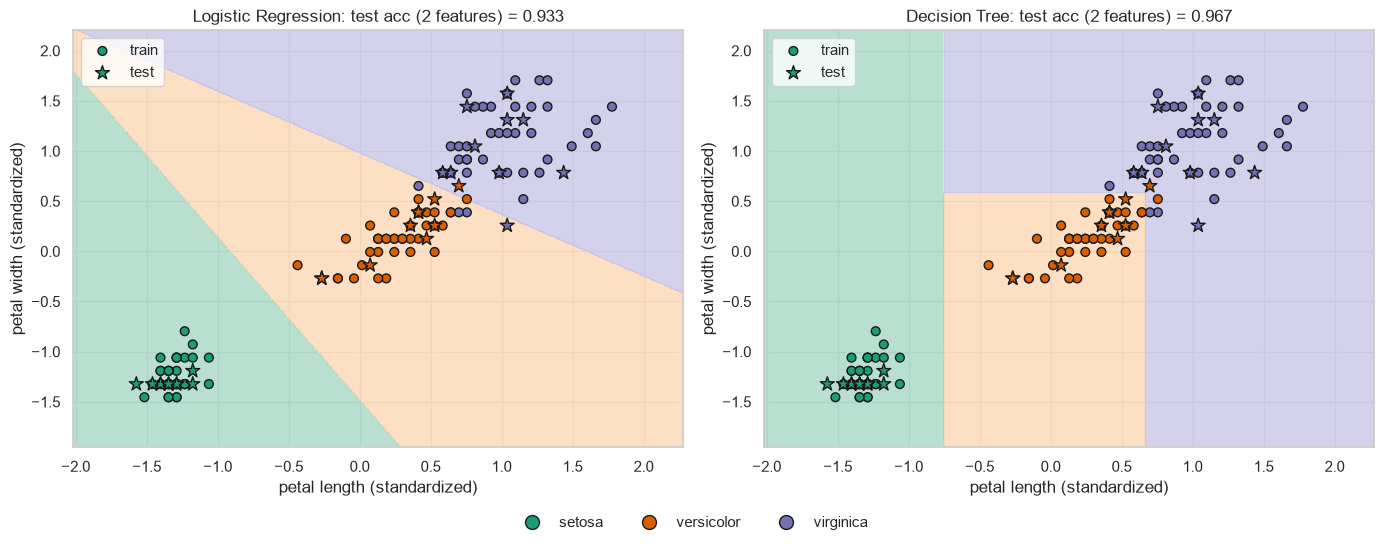

In [20]:
feat_pair = ["petal_length", "petal_width"]
Xtr2, Xte2 = X_train[feat_pair], X_test[feat_pair]

scaler2 = StandardScaler().fit(Xtr2)
Xtr2_s, Xte2_s = scaler2.transform(Xtr2), scaler2.transform(Xte2)

class_to_int = {c: i for i, c in enumerate(class_names)}
ytr_int = y_train.map(class_to_int).values
yte_int = y_test.map(class_to_int).values

models_2d = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}
for m in models_2d.values():
    m.fit(Xtr2_s, ytr_int)

# Mesh grid over the scaled feature space
pad = 0.5
x_min, x_max = Xtr2_s[:, 0].min() - pad, Xtr2_s[:, 0].max() + pad
y_min, y_max = Xtr2_s[:, 1].min() - pad, Xtr2_s[:, 1].max() + pad
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
grid = np.c_[xx.ravel(), yy.ravel()]

from matplotlib.colors import ListedColormap
cmap_bg = ListedColormap(["#a6d8c4", "#fdd9b5", "#c9c6e8"])
cmap_pts = ListedColormap(["#1b9e77", "#d95f02", "#7570b3"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, m) in zip(axes, models_2d.items()):
    Z = m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=cmap_bg, alpha=0.8)
    ax.scatter(Xtr2_s[:, 0], Xtr2_s[:, 1], c=ytr_int, cmap=cmap_pts,
               edgecolor="k", s=40, label="train")
    ax.scatter(Xte2_s[:, 0], Xte2_s[:, 1], c=yte_int, cmap=cmap_pts,
               edgecolor="k", s=110, marker="*", label="test")
    acc = accuracy_score(yte_int, m.predict(Xte2_s))
    ax.set_title(f"{name}: test acc (2 features) = {acc:.3f}")
    ax.set_xlabel("petal length (standardized)")
    ax.set_ylabel("petal width (standardized)")
    ax.legend(loc="upper left")

handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markeredgecolor="k",
                      markersize=10, label=n) for c, n in zip(["#1b9e77", "#d95f02", "#7570b3"], class_names)]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

## 9. Robustness check: stratified 5-fold cross-validation

In [21]:
# Pipelines keep the scaler inside each fold, so there is no leakage.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pipelines = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "Decision Tree": Pipeline([("scaler", StandardScaler()),
                               ("clf", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))]),
}
cv_rows = []
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy")
    cv_rows.append({"Model": name, "CV mean accuracy": scores.mean(), "CV std": scores.std()})
cv_results = pd.DataFrame(cv_rows).set_index("Model").round(4)
cv_results

,CV mean accuracy,CV std
Model,,
Logistic Regression,0.9533,0.0452
Decision Tree,0.9600,0.0249


## 10. Benchmark summary

,Accuracy,Precision (macro),Recall (macro),F1 (macro),CV mean accuracy,CV std
Model,,,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9533,0.0452
Decision Tree,0.9667,0.9697,0.9667,0.9666,0.9600,0.0249


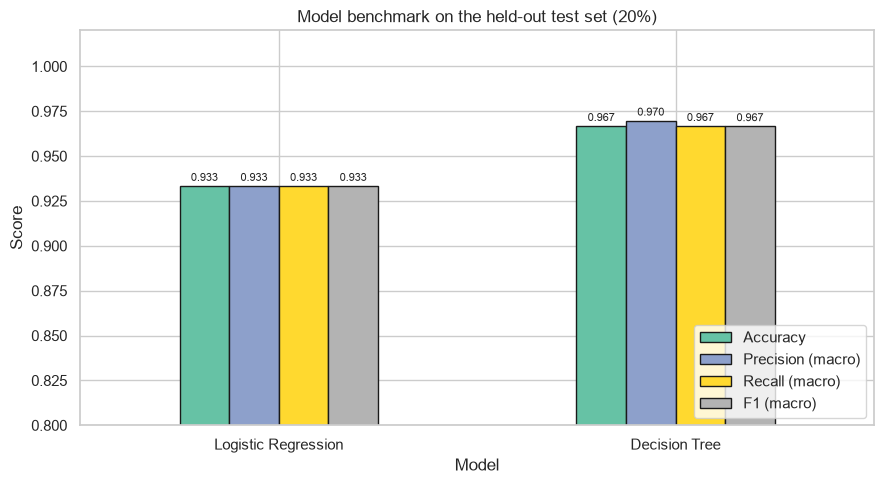

In [22]:
summary = results.join(cv_results)
display(summary)

ax = results.plot(kind="bar", figsize=(9, 5), rot=0, colormap="Set2", edgecolor="k")
ax.set_ylim(0.8, 1.02)
ax.set_ylabel("Score")
ax.set_title("Model benchmark on the held-out test set (20%)")
ax.legend(loc="lower right")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", padding=2, fontsize=8)
plt.tight_layout()
plt.show()

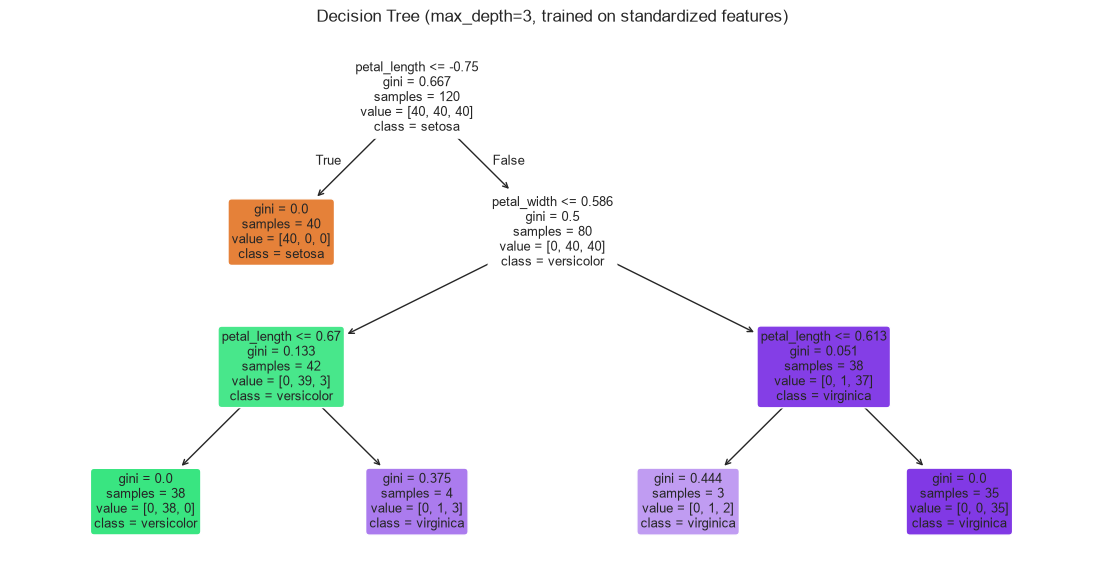

In [23]:
# Bonus: the learned decision tree (4 features)
plt.figure(figsize=(14, 7))
plot_tree(dec_tree, feature_names=list(X.columns), class_names=class_names,
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (max_depth=3, trained on standardized features)")
plt.show()

## Conclusions
- **Preprocessing:** `StandardScaler` was fit only on the training split, then applied to the test split. Scaling matters for Logistic Regression (regularization and gradient-based optimization are scale-sensitive). It does not change Decision Tree results, since trees split on thresholds, but it keeps one preprocessing path for both models.
- **Performance:** Both models score highly on Iris. Check the table in section 6 for the exact figures from your run. Any errors are confined to *versicolor* vs. *virginica*, while *setosa* is separated perfectly.
- **Model behavior:** Logistic Regression draws smooth, linear boundaries, while the Decision Tree draws axis-aligned rectangular regions, which the boundary plots make visible.
- **Caveat:** With only 30 test samples, a single misclassified flower shifts accuracy by about 3.3 points. The 5-fold cross-validation in section 9 gives a more stable estimate, so prefer it when comparing the two models.
- **Next steps:** Try the Wine dataset (`sklearn.datasets.load_wine`), tune hyperparameters with `GridSearchCV`, and add ROC/AUC curves (one-vs-rest).